# Task 3: Audio Quality, Augmentation, Feature Extraction and Voice Verification

This notebook is the Audio Lead deliverable. It:

1. loads every team recording of the two agreed phrases, **"Yes, approve"** and **"Confirm transaction"**,
2. checks the audio quality (clipping, noise, length) and documents the fixes,
3. plots a waveform and spectrogram for each recording and interprets them,
4. applies 7 augmentations and extracts librosa features into `data/audio_features.csv`,
5. trains and evaluates the **voice verification model** and saves `models/voice_model.pkl`.

All processing lives in `src/audio_pipeline.py` and `src/train_voice.py`, so the CLI app
uses exactly the same cleaning and features as this notebook.

In [1]:
# --- Setup: paths, imports, fixed seed ---
from pathlib import Path
import os, sys, json, warnings
import numpy as np
import pandas as pd
import librosa, librosa.display
import matplotlib.pyplot as plt
from IPython.display import display, Audio

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import audio_pipeline as ap
import train_voice as tv

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(ap.SEED)
warnings.filterwarnings("ignore", category=UserWarning)   # librosa n_fft notices on very short frames
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("Sample rate:", ap.SR, "Hz | phrases:", ap.PHRASES)

Sample rate: 16000 Hz | phrases: ('yes_approve', 'confirm_transaction')


## 1. Collection and naming

Each member recorded both phrases on their phone. The originals came in three formats:
`.mp4`/AAC at 16 kHz (Robert), `.mp4`/AAC at 44.1 kHz (Sandrine) and `.ogg`/Opus at 48 kHz
(Aderline, Eloi and the outsider, sent as voice notes). Eloi's files arrived as `eloi_*` and were
saved as `elox_*`, the member name the README and the image data use, so face and voice IDs match. They were
converted to mono 16-bit `.wav` and renamed to the repo convention
`<member>_<yes_approve|confirm_transaction>.wav`. The recordings of a person who is **not**
on the team go in `audio/unauthorized/` and are only used to test that access is denied.

In [2]:
# --- Inventory: every team recording and every unauthorized recording ---
team_files = ap.list_recordings(ap.AUDIO_DIR)
outsider_files = ap.list_recordings(ap.UNAUTHORIZED_DIR)
inventory = pd.DataFrame([{"file": p.name, "member": ap.parse_name(p)[0], "phrase": ap.parse_name(p)[1],
                           "role": "team" if p in team_files else "unauthorized"}
                          for p in team_files + outsider_files])
display(inventory)
members = sorted(inventory.query("role == 'team'").member.unique())
print(f"{len(team_files)} team recordings from {len(members)} members: {members}")
print("Recordings per member:", inventory.query("role == 'team'").groupby("member").size().to_dict())

,file,member,phrase,role
0,aderline_confirm_transaction.wav,aderline,confirm_transaction,team
1,aderline_yes_approve.wav,aderline,yes_approve,team
2,elox_confirm_transaction.wav,elox,confirm_transaction,team
3,elox_yes_approve.wav,elox,yes_approve,team
4,robert_confirm_transaction.wav,robert,confirm_transaction,team
5,robert_yes_approve.wav,robert,yes_approve,team
6,sandrine_confirm_transaction.wav,sandrine,confirm_transaction,team
7,sandrine_yes_approve.wav,sandrine,yes_approve,team
8,outsider_confirm_transaction.wav,outsider,confirm_transaction,unauthorized
9,outsider_yes_approve.wav,outsider,yes_approve,unauthorized


8 team recordings from 4 members: ['aderline', 'elox', 'robert', 'sandrine']
Recordings per member: {'aderline': 2, 'elox': 2, 'robert': 2, 'sandrine': 2}


**Completeness.** Every member listed above has recorded both phrases, so there are no gaps.
If another member's recordings arrive later, drop them into `audio/` with the same naming. The pipeline reads whatever is in
`audio/`, so adding the missing members' files and re-running this notebook updates every
table, plot and metric below with no code changes.

## 2. Audio quality check

For each recording: total length, length of actual speech (after trimming silence below
peak − 25 dB), peak level (a peak of 0.99 or above means the clip is clipped), an SNR
estimate (loudest 10% of frames vs quietest 10%) and the median pitch from `librosa.pyin`.

In [3]:
# --- Quality report on the raw (uncleaned) audio ---
quality = ap.quality_report(team_files + outsider_files)
quality["role"] = ["team"] * len(team_files) + ["unauthorized"] * len(outsider_files)
display(quality)

/opt/anaconda3/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:290: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


,member,phrase,duration_s,speech_s,peak,clipped,snr_db,median_pitch_hz,role
0,aderline,confirm_transaction,4.79,1.57,0.445,False,48.2,202.0,team
1,aderline,yes_approve,4.39,1.18,0.751,False,38.6,219.0,team
2,elox,confirm_transaction,2.27,0.99,0.947,False,57.6,107.0,team
3,elox,yes_approve,2.28,1.06,0.733,False,51.7,94.0,team
4,robert,confirm_transaction,4.10,1.34,0.154,False,51.8,128.0,team
5,robert,yes_approve,3.58,1.06,0.125,False,53.0,117.0,team
6,sandrine,confirm_transaction,3.13,2.30,0.097,False,34.6,205.0,team
7,sandrine,yes_approve,3.13,3.10,0.258,False,27.8,196.0,team
8,outsider,confirm_transaction,3.39,2.14,1.026,True,54.5,216.0,unauthorized
9,outsider,yes_approve,3.29,1.15,0.866,False,48.3,220.0,unauthorized


**Problems found and how they were handled**

| Problem | Where | Fix |
|---|---|---|
| Long silence around the speech (only 1.0–1.6 s of speech in 2.3–4.8 s clips) | Aderline's, Eloi's and Robert's clips, Sandrine's "confirm transaction" | `librosa.effects.trim` at 25 dB below peak, so the features describe the voice, not silence |
| Recording levels differ a lot (peak 0.10–0.26 for Robert and Sandrine, 0.45–0.95 for Aderline and Eloi) | all team clips | Peak-normalised to 0.9 after removing DC offset, so loudness differences between phones don't separate the speakers |
| Different phone sample rates (16, 44.1 and 48 kHz) | Robert 16 kHz, Sandrine 44.1 kHz, Aderline and Eloi 48 kHz | Everything resampled to **16 kHz**. A 16 kHz file has no content above 8 kHz, so at higher rates the model could learn "which phone" instead of "which voice" |
| Background noise is higher on Sandrine's clips (SNR ≈ 28–35 dB vs ≈ 52 dB) | Sandrine | Still above the 15 dB level where re-recording is needed, so the clips were kept. The `noise` augmentation teaches the model to tolerate this |
| Clipped (peak = 1.0) | `outsider_confirm_transaction` | Not a team clip and only used as an impostor in the demo, so it was kept as-is and noted |

No team clip is clipped, so nothing had to be re-recorded.

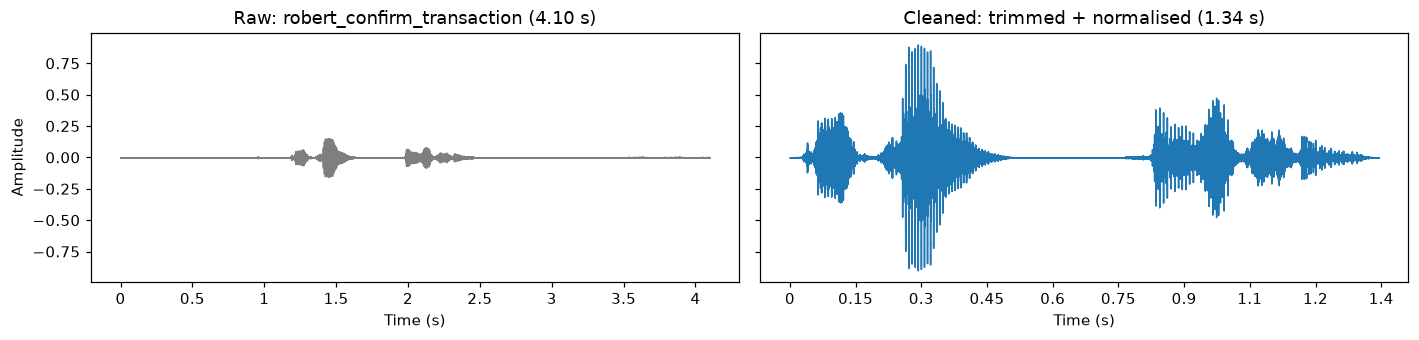

In [4]:
# --- Before/after cleaning for one clip, to show what trimming + normalising does ---
example = ap.AUDIO_DIR / "robert_confirm_transaction.wav"
if not example.exists():
    example = team_files[0]
raw, cleaned = ap.load_raw(example), ap.load_clean(example)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
librosa.display.waveshow(raw, sr=ap.SR, ax=ax[0], color="tab:gray")
ax[0].set(title=f"Raw: {example.stem} ({len(raw)/ap.SR:.2f} s)", xlabel="Time (s)", ylabel="Amplitude")
librosa.display.waveshow(cleaned, sr=ap.SR, ax=ax[1], color="tab:blue")
ax[1].set(title=f"Cleaned: trimmed + normalised ({len(cleaned)/ap.SR:.2f} s)", xlabel="Time (s)")
plt.tight_layout(); fig.savefig(FIG_DIR / "task3_cleaning_before_after.png"); plt.show()

**Interpretation.** The raw clip is mostly silence, and the speech peaks at only about 0.15
of full scale. After cleaning, only the spoken part is left and it fills the amplitude range.
Without this step the MFCC averages would be dominated by silent frames, and RMS energy
would mostly reflect how far each person held their phone.

## 3. Waveform and spectrogram of every recording

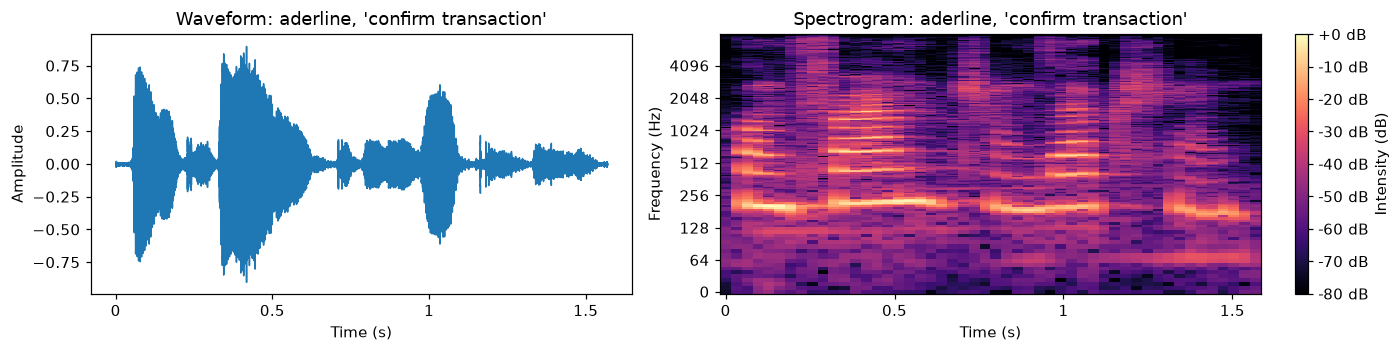

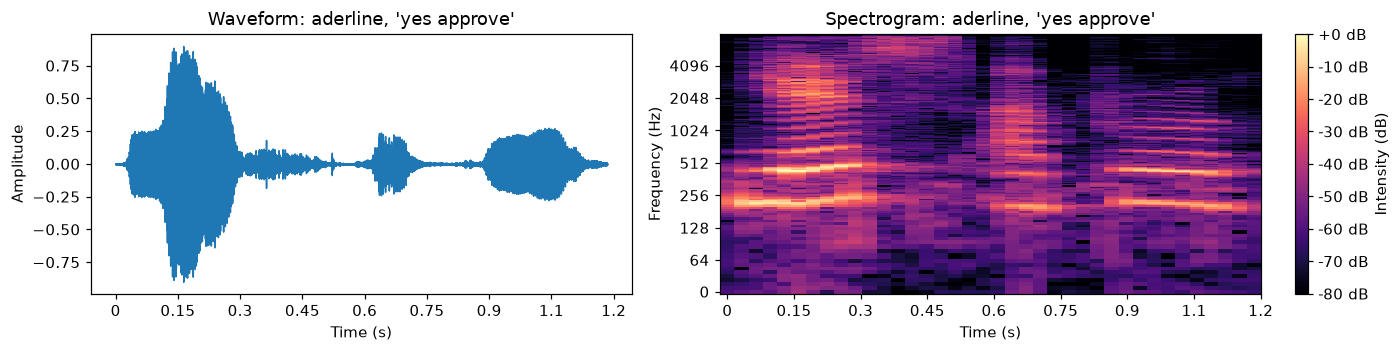

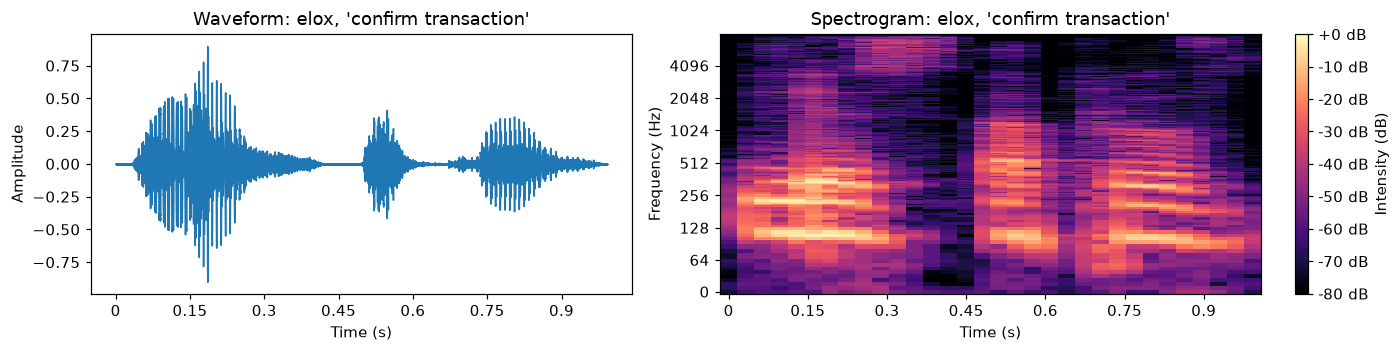

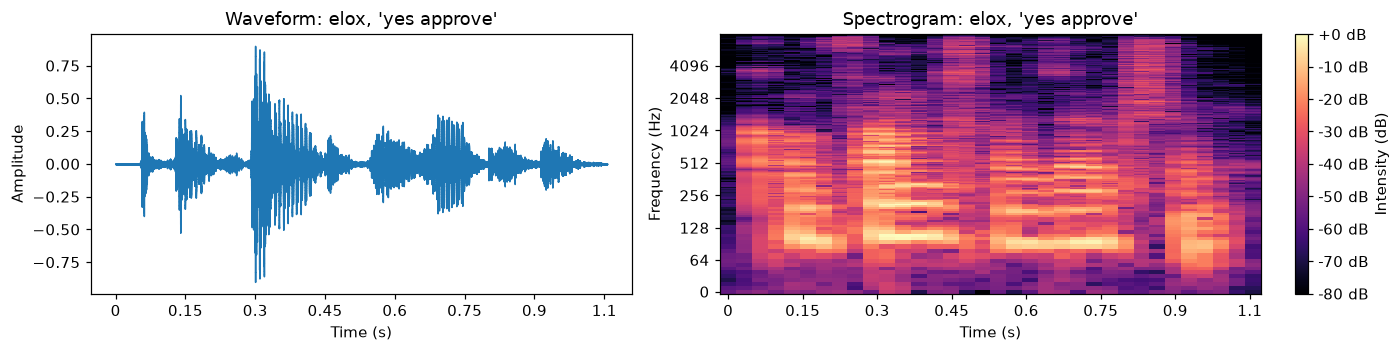

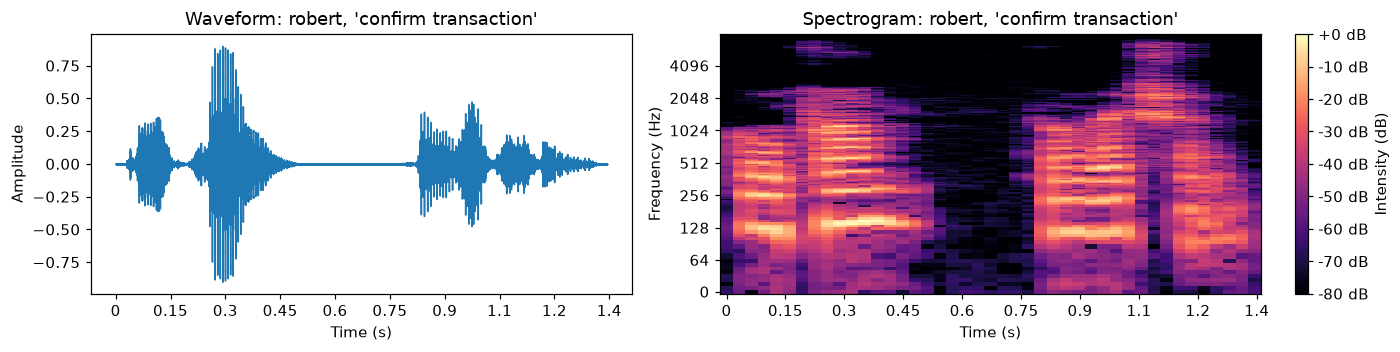

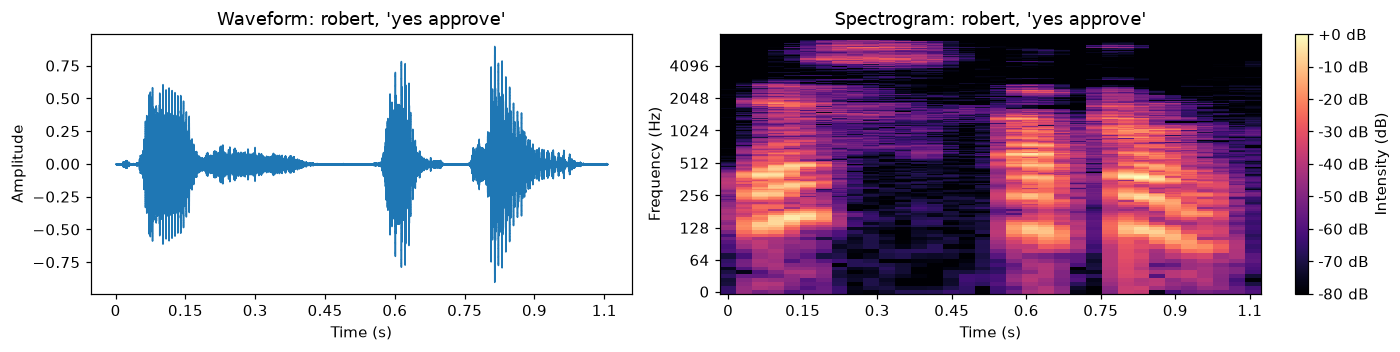

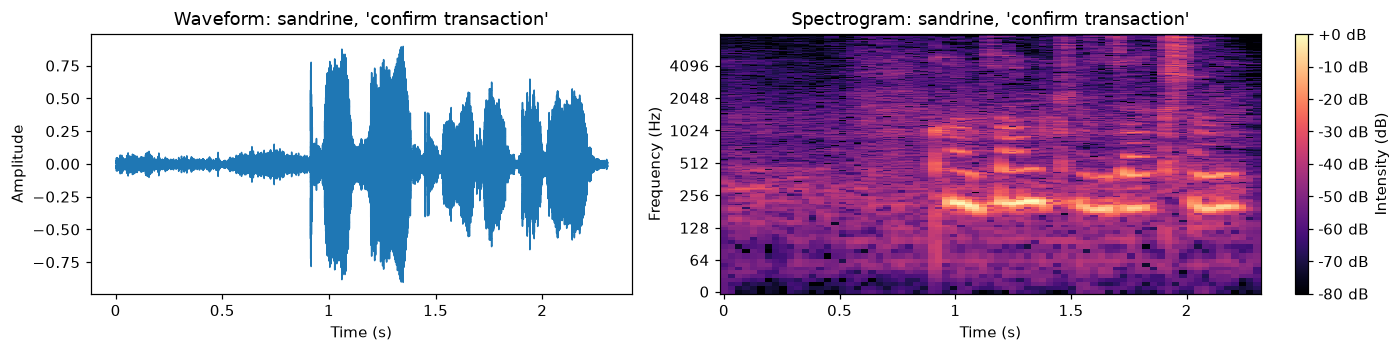

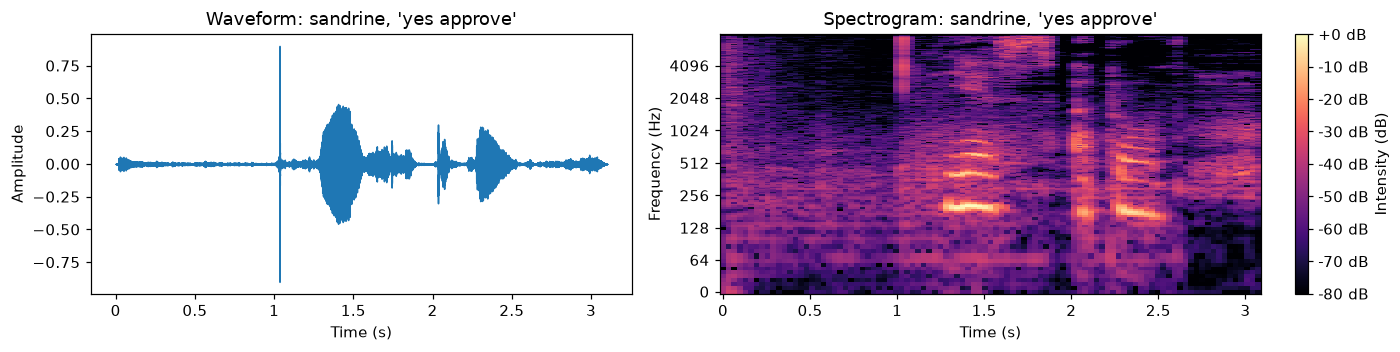

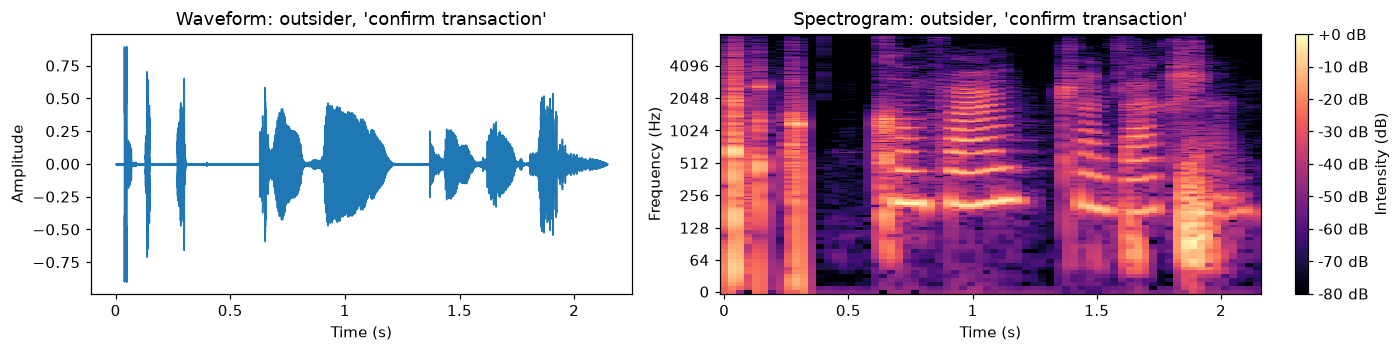

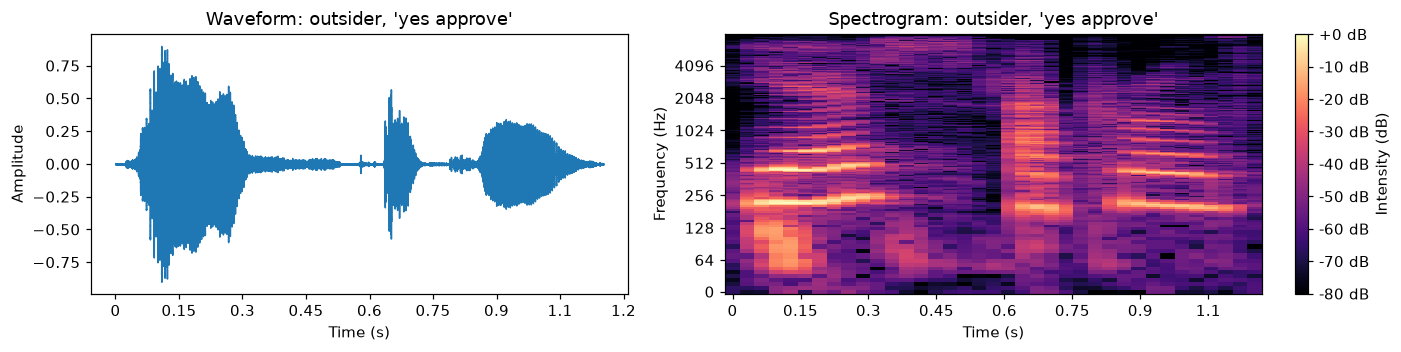

In [5]:
# --- Waveform (left) and log-frequency spectrogram (right) for each cleaned recording ---
for path in team_files + outsider_files:
    member, phrase = ap.parse_name(path)
    y = ap.load_clean(path)
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.3), gridspec_kw={"width_ratios": [1, 1.25]})
    librosa.display.waveshow(y, sr=ap.SR, ax=ax[0])
    ax[0].set(title=f"Waveform: {member}, '{phrase.replace('_', ' ')}'", xlabel="Time (s)", ylabel="Amplitude")
    S_db = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    img = librosa.display.specshow(S_db, sr=ap.SR, x_axis="time", y_axis="log", ax=ax[1], cmap="magma")
    ax[1].set(title=f"Spectrogram: {member}, '{phrase.replace('_', ' ')}'", xlabel="Time (s)", ylabel="Frequency (Hz)")
    fig.colorbar(img, ax=ax[1], format="%+2.0f dB", label="Intensity (dB)")
    plt.tight_layout(); fig.savefig(FIG_DIR / f"task3_wave_spec_{path.stem}.png"); plt.show()

In [6]:
# --- Numbers behind the interpretation: where the energy sits in each recording ---
def spectral_summary(path):
    y = ap.load_clean(path)
    power = np.abs(librosa.stft(y)) ** 2
    freqs = librosa.fft_frequencies(sr=ap.SR)
    share = lambda lo, hi: power[(freqs >= lo) & (freqs < hi)].sum() / power.sum()
    member, phrase = ap.parse_name(path)
    return {"member": member, "phrase": phrase,
            "speech_s": round(len(y) / ap.SR, 2),
            "energy_below_500Hz": round(share(0, 500), 2),
            "energy_500_2000Hz": round(share(500, 2000), 2),
            "energy_above_2000Hz": round(share(2000, ap.SR / 2), 2),
            "spectral_centroid_hz": round(float(librosa.feature.spectral_centroid(y=y, sr=ap.SR).mean())),
            "rolloff_hz": round(float(librosa.feature.spectral_rolloff(y=y, sr=ap.SR).mean()))}

spectral = pd.DataFrame([spectral_summary(p) for p in team_files + outsider_files])
spectral = spectral.merge(quality[["member", "phrase", "median_pitch_hz"]], on=["member", "phrase"])
display(spectral)

,member,phrase,speech_s,energy_below_500Hz,energy_500_2000Hz,energy_above_2000Hz,spectral_centroid_hz,rolloff_hz,median_pitch_hz
0,aderline,confirm_transaction,1.57,0.57,0.42,0.02,1515,2837,202.0
1,aderline,yes_approve,1.18,0.78,0.06,0.16,2048,3344,219.0
2,elox,confirm_transaction,0.99,0.94,0.05,0.01,1851,2993,107.0
3,elox,yes_approve,1.06,0.72,0.26,0.01,1465,2773,94.0
4,robert,confirm_transaction,1.34,0.63,0.36,0.01,1137,2087,128.0
5,robert,yes_approve,1.06,0.77,0.21,0.02,1844,2750,117.0
6,sandrine,confirm_transaction,2.30,0.93,0.04,0.03,1971,4205,205.0
7,sandrine,yes_approve,3.10,0.78,0.15,0.07,2149,4044,196.0
8,outsider,confirm_transaction,2.14,0.63,0.34,0.03,1355,2455,216.0
9,outsider,yes_approve,1.15,0.85,0.14,0.01,2119,3726,220.0


**Interpretation**

- **Waveforms.** Each phrase appears as separate bursts, one per word or syllable, with short
  gaps between them. "Confirm transaction" has more bursts and lasts longer than "yes approve"
  for most speakers. Sandrine speaks much more slowly (2.3–3.1 s of speech) than Aderline
  (1.2–1.6 s), Robert (1.1–1.3 s) or Eloi (1.0–1.1 s), so speaking rate is one of the
  differences between speakers.
- **Spectrograms.** In every recording most of the energy sits below 500 Hz (57–94% of total
  power). That band holds the fundamental (the speaker's pitch) and its first harmonics. The
  horizontal stripes inside each word are those harmonics. Their spacing equals the pitch, so
  they sit closer together for Eloi and Robert than for Aderline and Sandrine.
- **Pitch.** The voices fall into two pitch groups. Eloi (median about 94–107 Hz) and Robert
  (about 117–128 Hz) are lower; Aderline (202–219 Hz) and Sandrine (196–205 Hz) are higher.
  Pitch separates the two groups, but within each group the speakers are close, so the model
  has to rely on the MFCCs (timbre) and roll-off to tell them apart.
- **Higher frequencies.** Sandrine's spectral roll-off (about 4,000–4,200 Hz) is the highest,
  Aderline's (about 2,800–3,300 Hz) and Eloi's (about 2,800–3,000 Hz) are in the middle, and
  Robert's is the lowest (about 2,100–2,750 Hz). Part of Sandrine's high value comes from background hiss, visible as a faint
  haze across her spectrograms. That haze is also why her SNR is the lowest.
- **Why it matters for modelling.** MFCCs summarise this spectral shape, and pitch captures the
  harmonic spacing. Both describe *who* is speaking, which is what the voice model needs.

## 4. Augmentation

Each cleaned recording gets 7 augmentations plus the original, which gives 8 versions per
clip. They simulate realistic variation the model should tolerate: a slightly higher or lower
voice (±2 semitones), speaking faster or slower (±10%), a noisy room (white noise at 20 dB SNR),
a quieter voice (−6 dB) and a delayed start (0.2 s).

/opt/anaconda3/lib/python3.14/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/opt/anaconda3/lib/python3.14/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/opt/anaconda3/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:290: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)
/opt/anaconda3/lib/python3.14/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/opt/anaconda3/lib/python3.14/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is depr

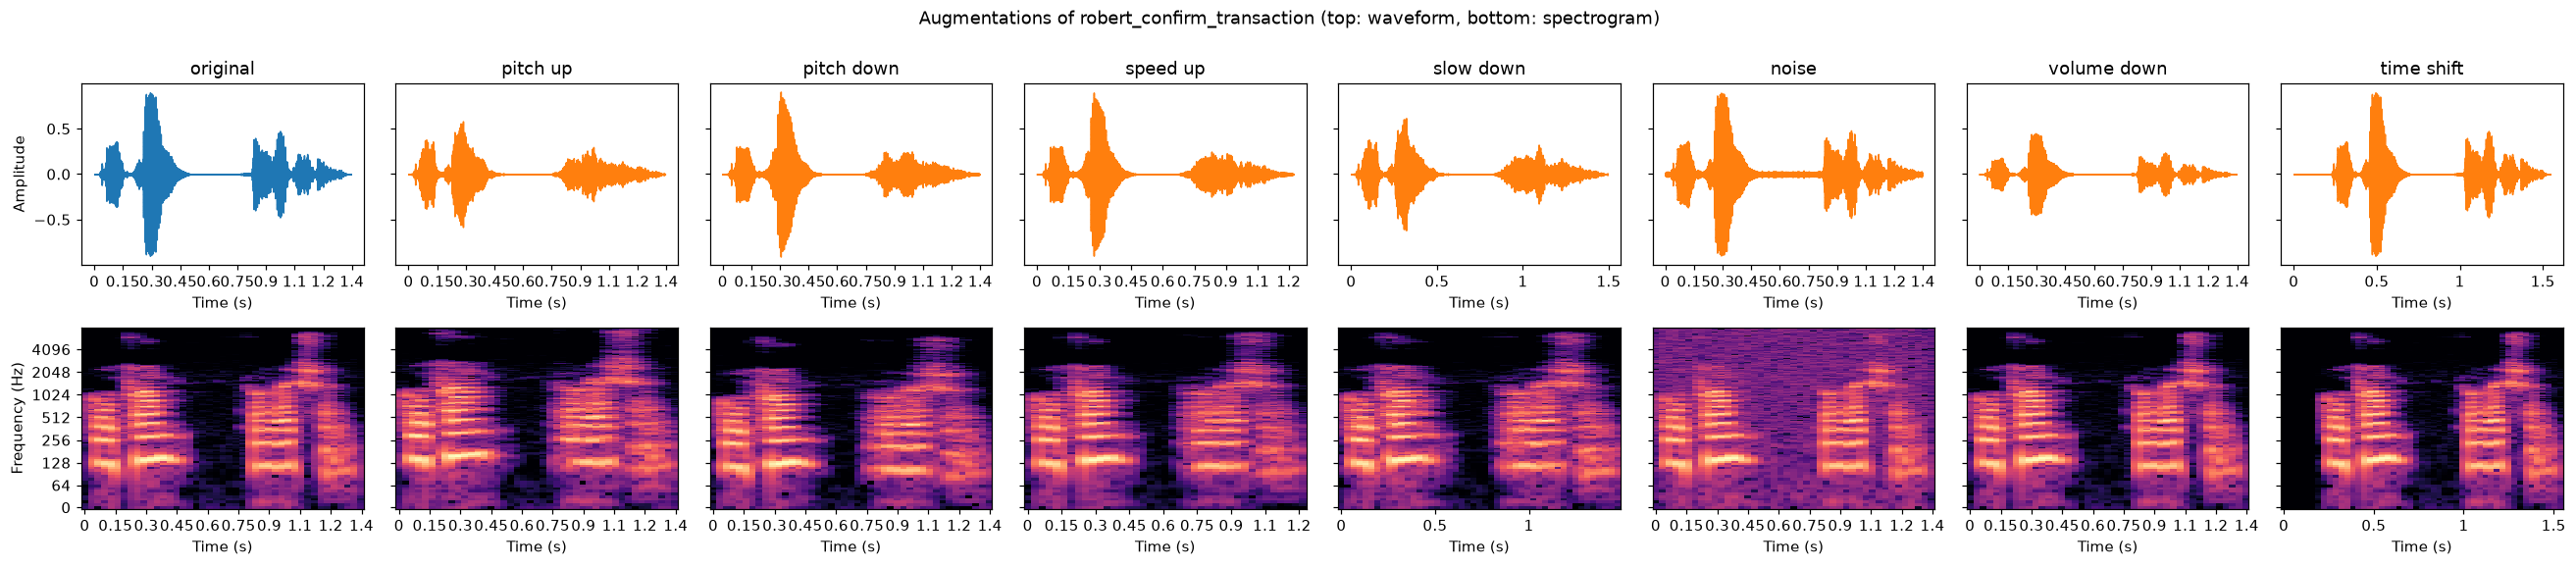

In [7]:
# --- Before/after: the original clip next to each augmentation (waveform + spectrogram) ---
y = ap.load_clean(example)
names = list(ap.AUGMENTATIONS)
fig, axes = plt.subplots(2, len(names), figsize=(3.0 * len(names), 5.2), sharey="row")
for col, name in enumerate(names):
    y_aug = ap.AUGMENTATIONS[name](y)
    librosa.display.waveshow(y_aug, sr=ap.SR, ax=axes[0, col], color="tab:blue" if name == "original" else "tab:orange")
    axes[0, col].set(title=name.replace("_", " "), xlabel="Time (s)", ylabel="Amplitude" if col == 0 else "")
    S_db = librosa.amplitude_to_db(np.abs(librosa.stft(y_aug)), ref=np.max)
    librosa.display.specshow(S_db, sr=ap.SR, x_axis="time", y_axis="log", ax=axes[1, col], cmap="magma")
    axes[1, col].set(xlabel="Time (s)", ylabel="Frequency (Hz)" if col == 0 else "")
fig.suptitle(f"Augmentations of {example.stem} (top: waveform, bottom: spectrogram)", y=1.0)
plt.tight_layout(); fig.savefig(FIG_DIR / "task3_augmentations.png", bbox_inches="tight"); plt.show()

In [8]:
# --- Listen to the original and two augmentations ---
for name in ["original", "pitch_up", "noise"]:
    print(name); display(Audio(ap.AUGMENTATIONS[name](y), rate=ap.SR))

original


pitch_up


noise


**Interpretation.** *Pitch up/down* move the harmonic stripes up or down while the timing stays
the same. *Speed up/slow down* squeeze or stretch the time axis while the pitch stays the same.
*Noise* fills the quiet gaps and the high frequencies with an even haze, *volume down* halves the
amplitude without changing the spectrogram's shape, and *time shift* adds 0.2 s of silence at the
start. Each version is still clearly the same person saying the same words, so they are valid
extra training examples. Together they multiply the data by 8.

## 5. Feature extraction → `data/audio_features.csv`

For every (recording, augmentation) pair, `ap.extract_features` computes:

- **MFCC 1–13**: mean and standard deviation over time (26 columns). These describe the
  spectral envelope (vocal-tract shape and timbre).
- **Spectral roll-off**: mean and std, the frequency below which 85% of the energy lies.
- **Energy (RMS)**: mean and std.
- **Pitch (f0 from `pyin`)**: mean and std over voiced frames. This was added because Section 3
  showed it is the clearest difference between speakers.

In [9]:
# --- Build the feature table and save it ---
features = ap.build_feature_table(team_files)
ap.FEATURES_CSV.parent.mkdir(exist_ok=True)
features.to_csv(ap.FEATURES_CSV, index=False)

# --- Verify: reload from disk and check shape, columns, types and missing values ---
check = pd.read_csv(ap.FEATURES_CSV)
print("Shape:", check.shape)
print("Missing values:", int(check.isna().sum().sum()))
print("Duplicate rows:", int(check.duplicated().sum()))
print("Rows per member / augmentation:")
display(check.groupby(["member", "phrase"]).size().unstack())
print("Non-numeric columns:", check.select_dtypes(exclude="number").columns.tolist())
display(check.head())

Shape: (64, 35)
Missing values: 0
Duplicate rows: 0
Rows per member / augmentation:


phrase,confirm_transaction,yes_approve
member,,
aderline,8,8
elox,8,8
robert,8,8
sandrine,8,8


Non-numeric columns: ['member', 'phrase', 'augmentation']


,member,phrase,augmentation,mfcc_1_mean,mfcc_2_mean,mfcc_3_mean,mfcc_4_mean,mfcc_5_mean,mfcc_6_mean,mfcc_7_mean,...,mfcc_10_std,mfcc_11_std,mfcc_12_std,mfcc_13_std,rolloff_mean,rolloff_std,energy_mean,energy_std,pitch_mean,pitch_std
0,aderline,confirm_transaction,original,-196.821365,100.556015,-22.182968,20.206659,-0.075745,-17.487768,-0.534403,...,8.831304,10.302322,8.514938,6.989880,2836.562500,1383.548392,0.124421,0.085056,202.404464,15.011900
1,aderline,confirm_transaction,pitch_up,-212.065964,88.658134,-23.831272,17.784098,-14.133642,-15.772509,4.453027,...,8.704759,7.928334,8.431588,8.427714,3038.906250,1239.936532,0.088159,0.064477,229.615176,16.936453
2,aderline,confirm_transaction,pitch_down,-223.666351,111.638214,-26.552475,24.313133,-2.067077,-6.210997,-14.208549,...,9.480105,9.753941,7.209245,10.286326,2559.062500,1078.274627,0.092208,0.066128,183.029486,13.966591
3,aderline,confirm_transaction,speed_up,-209.476196,95.166885,-22.562551,17.355711,-1.775622,-16.430346,-0.698217,...,7.450654,9.058537,7.662209,7.574742,2945.833333,1262.296721,0.096999,0.069784,204.219454,13.970073
4,aderline,confirm_transaction,slow_down,-216.029709,95.825615,-21.650305,17.489614,-4.311156,-17.882898,0.487277,...,8.038967,9.076297,7.618428,6.694989,2958.806818,1279.346957,0.077638,0.059132,204.295358,13.839154


**Interpretation.** The CSV has one row per (member, phrase, augmentation), with the 3 label
columns followed by 30 numeric feature columns. It has no missing values and no duplicate rows,
and every member has the same number of rows per phrase. The column names (`member`, `phrase`,
`augmentation`) match the image CSV convention, so Member 4 can join on `member`.

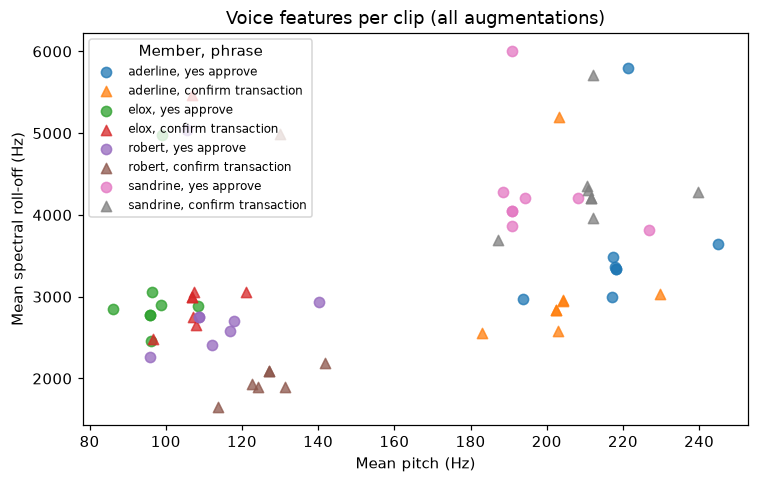

In [10]:
# --- Do the features actually separate the speakers? Pitch vs roll-off, every row ---
fig, ax = plt.subplots(figsize=(7, 4.5))
for member, grp in check.groupby("member"):
    for phrase, marker in zip(ap.PHRASES, ["o", "^"]):
        g = grp[grp.phrase == phrase]
        ax.scatter(g.pitch_mean, g.rolloff_mean, marker=marker, s=45, alpha=0.75,
                   label=f"{member}, {phrase.replace('_', ' ')}")
ax.set(title="Voice features per clip (all augmentations)", xlabel="Mean pitch (Hz)",
       ylabel="Mean spectral roll-off (Hz)")
ax.legend(title="Member, phrase", fontsize=8)
plt.tight_layout(); fig.savefig(FIG_DIR / "task3_feature_scatter.png"); plt.show()

**Interpretation.** Pitch splits the clips into a low group (Eloi about 86–121 Hz, Robert
about 96–142 Hz) and a high group (Aderline and Sandrine, about 183–245 Hz). Inside each group
the speakers overlap on pitch. Sandrine sits somewhat higher on roll-off than Aderline, and
Robert's "confirm transaction" clips sit lowest on roll-off.
The pitch-shift augmentations spread each group out. Each person's two phrases fall in
somewhat different places, which shows how much *what* is said changes the features, and
that is exactly what the cross-phrase test below measures. The overlap between Aderline and
Sandrine predicts where the model will make mistakes.

## 6. Voice verification model

**Setup**

| | |
|---|---|
| Algorithm | Random Forest (300 trees, `random_state=42`), after `StandardScaler` |
| Input | the 30 numeric features from `audio_features.csv` |
| Target | `member` |
| Split | **leave-one-phrase-out**: train on all versions of one phrase, test on all versions of the other phrase, then swap. The reported metrics are the mean of the two folds |
| Loss | log loss (cross-entropy) on predicted probabilities |

**Why not a random 80/20 split?** The 8 augmented versions of one recording are near-duplicates.
A random split puts copies of the same recording in both train and test, and the scores come out
near 100% for no real reason. Holding out a whole phrase asks the harder, honest question: does
the model recognise the speaker when they say words it has never heard from them?

In [11]:
# --- Train, evaluate (both folds), fit final model on all rows, save model + metrics ---
metrics, folds, voice_model = tv.main()
fold_table = pd.DataFrame([{k: f[k] for k in ("train_phrase", "test_phrase", "train_rows", "test_rows",
                                                "accuracy", "f1_macro", "log_loss")} for f in folds])
fold_table.loc[len(fold_table)] = ["mean", "", "", ""] + [metrics["mean_over_folds"][k] for k in ("accuracy", "f1_macro", "log_loss")]
display(fold_table.round(3))

/opt/anaconda3/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:290: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)
/opt/anaconda3/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:290: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


{
  "members": [
    "aderline",
    "elox",
    "robert",
    "sandrine"
  ],
  "rows": 64,
  "mean_over_folds": {
    "accuracy": 0.71875,
    "f1_macro": 0.6506353265944058,
    "log_loss": 0.9309461900637845
  },
  "acceptance_threshold": 0.29,
  "unauthorized_checks": [
    {
      "file": "outsider_confirm_transaction.wav",
      "predicted_member": "aderline",
      "confidence": 0.66,
      "granted": true
    },
    {
      "file": "outsider_yes_approve.wav",
      "predicted_member": "aderline",
      "confidence": 0.44,
      "granted": true
    }
  ]
}


,train_phrase,test_phrase,train_rows,test_rows,accuracy,f1_macro,log_loss
0,confirm_transaction,yes_approve,32,32,0.719,0.666,0.990
1,yes_approve,confirm_transaction,32,32,0.719,0.635,0.872
2,mean,,,,0.719,0.651,0.931


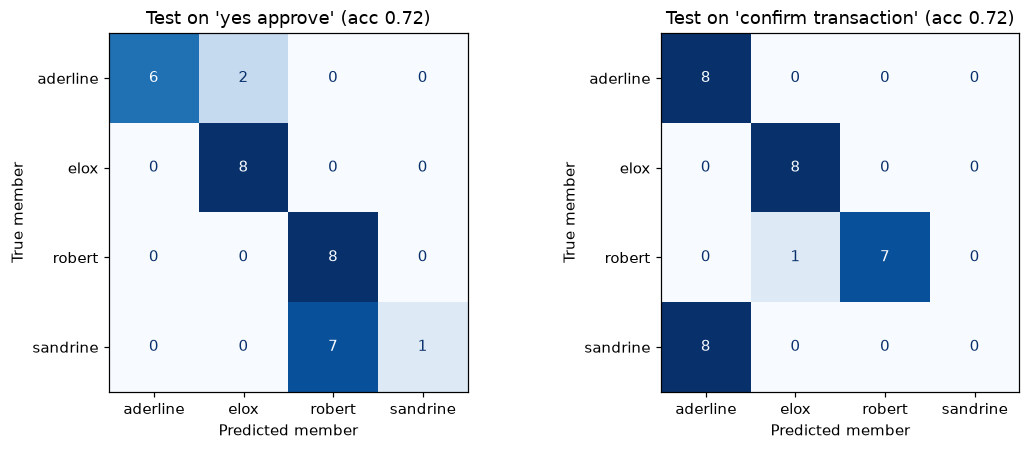

In [12]:
# --- Confusion matrix per fold ---
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, len(folds), figsize=(5.2 * len(folds), 4.2))
for ax, f in zip(np.atleast_1d(axes), folds):
    ConfusionMatrixDisplay(np.array(f["confusion_matrix"]), display_labels=f["labels"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set(title=f"Test on '{f['test_phrase'].replace('_', ' ')}' (acc {f['accuracy']:.2f})",
           xlabel="Predicted member", ylabel="True member")
plt.tight_layout(); fig.savefig(FIG_DIR / "task3_voice_confusion_matrices.png"); plt.show()

In [13]:
# --- Which test clips were wrong? ---
errors = []
for f in folds:
    test = check[check.phrase == f["test_phrase"]].assign(predicted=f["y_pred"])
    errors.append(test.loc[test.member != test.predicted, ["member", "phrase", "augmentation", "predicted"]])
display(pd.concat(errors) if errors else "No errors")

,member,phrase,augmentation,predicted
10,aderline,yes_approve,pitch_down,elox
11,aderline,yes_approve,speed_up,elox
56,sandrine,yes_approve,original,robert
57,sandrine,yes_approve,pitch_up,robert
58,sandrine,yes_approve,pitch_down,robert
59,sandrine,yes_approve,speed_up,robert
60,sandrine,yes_approve,slow_down,robert
62,sandrine,yes_approve,volume_down,robert
63,sandrine,yes_approve,time_shift,robert
37,robert,confirm_transaction,noise,elox


**Interpretation**

- **Eloi is recognised in all 16 test clips**, **Robert in 15** and **Aderline in 14**, so the
  model reliably tells apart three of the four speakers, including Eloi and Robert, whose
  pitches are close.
- **Sandrine is the weak point.** Her "yes approve" clips are mostly labelled Robert, and her
  "confirm transaction" clips are mostly labelled Aderline. Her two recordings differ more from
  each other than anyone else's: one is the noisiest (SNR ≈ 28 dB) and has almost no pause, the
  other has 93% of its energy below 500 Hz. With one recording of her to learn from per fold,
  the model can't bridge that gap.
- Mean accuracy is about three times chance (0.25 for 4 speakers), but well below the near-perfect
  numbers a random split would show. These are the honest numbers for a model trained on
  2 recordings per person.
- **Design choices tested.** On the earlier 2-member data, the first version of the pipeline
  (22.05 kHz, no pitch features) scored 0.72 mean accuracy. Moving to a common 16 kHz band and
  adding pitch raised that to 0.78. The weak fold stayed weak, which points to a data problem
  (too few recordings per person), not a model problem. The fix is 3–5 takes of each phrase
  per member.

## 7. Unauthorized voice check

The model always answers with one of the known members. To reject an impostor, `verify_voice`
also requires the top probability to reach an **acceptance threshold**. The threshold is set to
the lowest confidence the model gave a *genuine* held-out clip, so real members are never locked
out. In the app, the predicted voice must also match the member found by face recognition.

In [14]:
# --- Run the saved model on the outsider's recordings ---
threshold = metrics["acceptance_threshold"]
print("Acceptance threshold:", threshold)
display(pd.DataFrame(metrics["unauthorized_checks"]))

# Same check with a claimed identity, as the app does after face recognition
rows = []
for path in outsider_files:
    for claimed in members:
        r = ap.verify_voice(path, voice_model, threshold, claimed_member=claimed)
        rows.append({"file": path.name, "face_says": claimed, **r})
display(pd.DataFrame(rows))

Acceptance threshold: 0.29


,file,predicted_member,confidence,granted
0,outsider_confirm_transaction.wav,aderline,0.66,True
1,outsider_yes_approve.wav,aderline,0.44,True


/opt/anaconda3/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:290: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)
/opt/anaconda3/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:290: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


,file,face_says,predicted_member,confidence,granted
0,outsider_confirm_transaction.wav,aderline,aderline,0.66,True
1,outsider_confirm_transaction.wav,elox,aderline,0.66,False
2,outsider_confirm_transaction.wav,robert,aderline,0.66,False
3,outsider_confirm_transaction.wav,sandrine,aderline,0.66,False
4,outsider_yes_approve.wav,aderline,aderline,0.44,True
5,outsider_yes_approve.wav,elox,aderline,0.44,False
6,outsider_yes_approve.wav,robert,aderline,0.44,False
7,outsider_yes_approve.wav,sandrine,aderline,0.44,False


**Interpretation (limitation).** With the current data, the outsider's voice is *not* rejected by
the confidence threshold on its own. A classifier trained on only four speakers splits every voice
between those four, and genuine held-out clips score as low as the threshold above. No threshold
lets every team member in and keeps the outsider out. The identity check helps:
the outsider is only let in when the face step has already accepted the matching member, so the
face → voice order in the system is what blocks most impostor attempts. Getting the voice step to
reject strangers reliably needs (a) recordings from all members, (b) more takes per person, and
ideally (c) a few non-member voices as an explicit "unknown" class.

## 8. Hand-over to Member 4 (Integration)

| Item | Value |
|---|---|
| Model file | `models/voice_model.pkl` (rebuild with `python src/train_voice.py`; `.pkl` is git-ignored) |
| Metrics | `reports/voice_model_metrics.json`: accuracy, macro-F1, log loss per fold and mean, threshold, outsider checks |
| Features | `data/audio_features.csv` |
| Prediction | `from audio_pipeline import verify_voice` → `verify_voice(path, model, threshold, claimed_member)` returns `predicted_member`, `confidence`, `granted` |
| Figures | `reports/figures/task3_*.png` |

In [15]:
# --- Final numbers to paste into the results table ---
print(json.dumps({"model": "voice_verification", **{k: round(v, 3) for k, v in metrics["mean_over_folds"].items()},
                  "members": metrics["members"], "acceptance_threshold": metrics["acceptance_threshold"]}, indent=2))

{
  "model": "voice_verification",
  "accuracy": 0.719,
  "f1_macro": 0.651,
  "log_loss": 0.931,
  "members": [
    "aderline",
    "elox",
    "robert",
    "sandrine"
  ],
  "acceptance_threshold": 0.29
}
